## 1. The Vision Transformer

The Vision Transformer (Dosovitskiy et al., ICLR 2021):

1. **Patch Embedding:** divide the image into patches. Each patch → linear projection → embedding vector.
2. **CLS Token:** prepend a learnable classification token.
3. **Positional Encoding:** add position information (learnable).
4. **Transformer Encoder:** stack of multi-head self-attention + feed-forward blocks.
5. **Output:** CLS token at the final layer = the image embedding.

Dimensions are scaled down so it trains in minutes:
- Image: 64×64 (instead of 224×224)
- Patch size: 8×8 (gives 64 patches)
- Embedding dim: 128 (instead of 768 in DINOv2 ViT-B/14)
- 4 transformer layers, 4 heads

**Training.** With random weights the CLS token is meaningless (evaluated below as the "untrained" baseline).
DINOv2 is trained self-supervised on 142M images; we don't have that, so the miniature ViT is trained
**supervised** on the train-split regions (cross-entropy over the 103 food classes through a linear head).
The head is discarded afterwards — only the L2-normalised CLS embedding is used for KNN, like DINOv2.

## Evaluation protocol (shared by notebooks 03a, 03b, 03c)

Every food-class region of a FoodSeg103 annotation with area ≥ 32×32 px becomes one sample:
bounding-box crop, background pixels zeroed, label = its FoodSeg103 class (103 classes).

- **Gallery** = all train-split regions ("enrolled" dishes), **queries** = test-split regions.
- Each query is matched to the gallery by **cosine similarity** (vectors are L2-normalised), exactly like the
  dish database lookup.
- Metrics (`foodseg_embed.knn_evaluate`): similarity-weighted **KNN accuracy** for K = 1, 3, 5, 10;
  **top-5 hit** (the right class is among the 5 nearest neighbours); **macro accuracy** (1-NN accuracy averaged over
  classes – FoodSeg103 is very imbalanced, so this is the fairer number).
- Results are written to `outputs/embed/<embedder>_test.json`; notebook 03c puts all of them in one table.

## 2. Library & configuration

In [2]:
import time, json, math, random

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2 as T
from tqdm.auto import tqdm

import foodseg_common as fc
import foodseg_embed as fe

print(f'PyTorch {torch.__version__} | CUDA available: {torch.cuda.is_available()}')

PyTorch 2.10.0 | CUDA available: True


In [12]:
VIT = dict(image_size=64, patch_size=8, embed_dim=128, depth=4, num_heads=4)
TRAIN = dict(epochs=10, batch_size=256, lr=1e-3, weight_decay=0.05, label_smoothing=0.1,
             warmup_pct=0.1, eval_every=5, seed=42)

TRAIN_LIMIT = None    # number of images (None = full split); e.g. 200 for a quick trial
EVAL_LIMIT  = None    # images in val/test

RUN_DIR = fc.PLAYGROUND / 'runs' / 'minivit'
RUN_DIR.mkdir(parents=True, exist_ok=True)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

NAMES = fe.category_names()
N_CLASSES = len(NAMES)                     # 104 (0 = background, never a label)
regions = {s: fe.region_index(s, limit=TRAIN_LIMIT if s == 'train' else EVAL_LIMIT) for s in ('train', 'val', 'test')}
labels = {s: fe.labels_of(r) for s, r in regions.items()}
for s, r in regions.items():
    print(f'{s:5s}: {len(r)} regions, {len(np.unique(labels[s]))} classes')
print('device:', device, '| run dir:', RUN_DIR)

train: 17982 regions, 103 classes
val  : 3926 regions, 98 classes
test : 3887 regions, 99 classes
device: cuda | run dir: C:\Users\HPZ4G4Workstation\Documents\mTech\PVsys\PVsys_1\playground\runs\minivit


train (17982, 64, 64, 3)
val (3926, 64, 64, 3)
test (3887, 64, 64, 3)


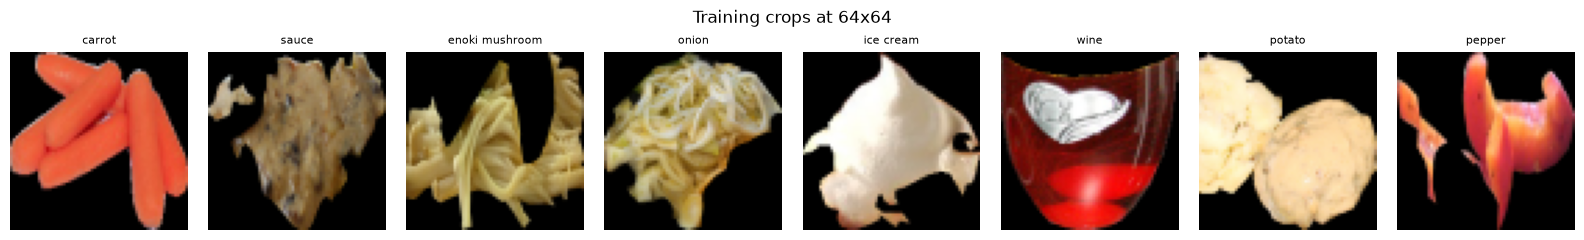

In [6]:
# 64x64 crops for all splits (cached as .npy in outputs/embed/ when the full split is used)
size = VIT['image_size']
crops = {}
for s, r in regions.items():
    limit = TRAIN_LIMIT if s == 'train' else EVAL_LIMIT
    crops[s] = fe.load_crops(s, r, size, cache_name=f'crops_{s}_{size}' if limit is None else None)
    print(s, crops[s].shape)

fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
for ax, i in zip(axes, np.random.default_rng(0).choice(len(crops['train']), 8, replace=False)):
    ax.imshow(crops['train'][i]); ax.set_title(NAMES[labels['train'][i]], fontsize=8); ax.axis('off')
plt.suptitle(f'Training crops at {size}x{size}'); plt.tight_layout(); plt.show()

## 3. Model — building blocks

In [8]:
# ── Building block 1: Multi-Head Self-Attention ───────────────────────

class MultiHeadSelfAttention(nn.Module):
    """
    The core ViT operation.

    Each token (patch) attends to every other token to learn relationships.

    Attention(Q, K, V) = softmax(Q·Kᵀ / √d_k) · V

    Multi-head: run H independent attention computations → concatenate results.
    This lets the model attend to different aspects simultaneously
    (e.g. one head focuses on colour, another on shape boundaries).
    """
    def __init__(self, embed_dim, num_heads, dropout=0.0):
        super().__init__()
        assert embed_dim % num_heads == 0, "embed_dim must be divisible by num_heads"
        self.num_heads = num_heads
        self.head_dim  = embed_dim // num_heads
        self.scale     = self.head_dim ** -0.5   # 1/√d_k

        # Single linear layer for Q, K, V (3× embed_dim output)
        self.qkv  = nn.Linear(embed_dim, 3 * embed_dim, bias=False)
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        B, N, D = x.shape  # batch, num_tokens, embed_dim

        # Project to Q, K, V then split heads
        qkv = self.qkv(x)                                 # (B, N, 3D)
        qkv = qkv.reshape(B, N, 3, self.num_heads, self.head_dim)
        qkv = qkv.permute(2, 0, 3, 1, 4)                 # (3, B, H, N, d_k)
        q, k, v = qkv[0], qkv[1], qkv[2]                 # each (B, H, N, d_k)

        # Attention scores: (B, H, N, N)
        attn = (q @ k.transpose(-2, -1)) * self.scale     # scale prevents saturation
        attn = F.softmax(attn, dim=-1)                     # normalise over keys
        attn = self.drop(attn)

        # Weighted sum of values
        out = (attn @ v)                                   # (B, H, N, d_k)
        out = out.transpose(1, 2).reshape(B, N, D)        # reassemble heads
        return self.proj(out)                              # final projection


# ── Building block 2: Feed-Forward Network (MLP) ─────────────────────

class FeedForward(nn.Module):
    """
    Two-layer MLP applied independently to each token.
    Standard ViT uses 4× expansion: dim → 4·dim → dim.
    """
    def __init__(self, embed_dim, mlp_ratio=4.0, dropout=0.0):
        super().__init__()
        hidden = int(embed_dim * mlp_ratio)
        self.net = nn.Sequential(
            nn.Linear(embed_dim, hidden),
            nn.GELU(),              # Smooth approximation to ReLU
            nn.Dropout(dropout),
            nn.Linear(hidden, embed_dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


# ── Building block 3: Transformer Block ──────────────────────────────

class TransformerBlock(nn.Module):
    """
    One ViT layer = Pre-LayerNorm + Attention + Pre-LayerNorm + FFN.
    Residual connections allow gradients to flow through many layers.
    """
    def __init__(self, embed_dim, num_heads, mlp_ratio=4.0, dropout=0.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attn  = MultiHeadSelfAttention(embed_dim, num_heads, dropout)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.ff    = FeedForward(embed_dim, mlp_ratio, dropout)

    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        x = x + self.ff  (self.norm2(x))
        return x

## 4. Model — miniature ViT embedder + training head

In [9]:
class MiniViTEmbedder(nn.Module):
    """
    Miniature Vision Transformer for image embedding.
    Architecture mirrors DINOv2/ViT-B but scaled down.
    """

    def __init__(self, image_size=64, patch_size=8, embed_dim=128, depth=4, num_heads=4):
        super().__init__()
        assert image_size % patch_size == 0, "image_size must be divisible by patch_size"
        self.image_size = image_size
        self.patch_size = patch_size
        self.embed_dim  = embed_dim
        n_patches = (image_size // patch_size) ** 2

        # Patch embedding: flatten each patch (patch_size² × 3 pixels) → embed_dim vector
        self.patch_embed = nn.Linear(patch_size * patch_size * 3, embed_dim)
        # CLS token: aggregates global information through the transformer layers
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        # Positional encoding: tells the model WHERE each patch comes from
        self.pos_embed = nn.Parameter(torch.zeros(1, n_patches + 1, embed_dim))
        self.blocks = nn.ModuleList([TransformerBlock(embed_dim, num_heads) for _ in range(depth)])
        self.norm = nn.LayerNorm(embed_dim)

        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            if m.bias is not None: nn.init.zeros_(m.bias)
        elif isinstance(m, nn.LayerNorm):
            nn.init.ones_(m.weight); nn.init.zeros_(m.bias)

    def _patchify(self, x):
        """(B, C, H, W) → (B, N, patch_size²×C) with N = (H/patch_size)²."""
        B, C, H, W = x.shape
        p = self.patch_size
        x = x.reshape(B, C, H // p, p, W // p, p)
        x = x.permute(0, 2, 4, 1, 3, 5)
        return x.reshape(B, (H // p) * (W // p), C * p * p)

    def features(self, x):
        """Final-layer CLS token (before L2 normalisation), shape (B, embed_dim)."""
        B = x.shape[0]
        tokens = self.patch_embed(self._patchify(x))                       # 1. patchify + embed
        tokens = torch.cat([self.cls_token.expand(B, -1, -1), tokens], 1)  # 2. prepend CLS
        tokens = tokens + self.pos_embed                                   # 3. positions
        for block in self.blocks:                                          # 4. transformer layers
            tokens = block(tokens)
        return self.norm(tokens[:, 0])                                     # 5. CLS token

    def forward(self, x):
        """L2-normalised embedding, shape (B, embed_dim)."""
        return F.normalize(self.features(x), dim=-1)


class MiniViTClassifier(nn.Module):
    """Embedder + linear head over the food classes; the head is only used for training."""

    def __init__(self, n_classes, **vit_kw):
        super().__init__()
        self.embedder = MiniViTEmbedder(**vit_kw)
        self.head = nn.Linear(self.embedder.embed_dim, n_classes)

    def forward(self, x):
        return self.head(self.embedder.features(x))


torch.manual_seed(TRAIN['seed'])
model = MiniViTClassifier(N_CLASSES, **VIT).to(device)
n_params = sum(p.numel() for p in model.embedder.parameters())
print(f'MiniViT embedder: {n_params:,} parameters | output_dim={VIT["embed_dim"]}')

MiniViT embedder: 824,960 parameters | output_dim=128


## 5. Data pipeline

In [10]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

AUGMENT = T.Compose([
    T.RandomResizedCrop(VIT['image_size'], scale=(0.6, 1.0), antialias=True),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),          # food is photographed from above: up/down carries no meaning
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02),
])


def to_input(batch_uint8):
    """(B, H, W, 3) or (B, 3, H, W) uint8 → normalised float tensor (B, 3, H, W)."""
    x = torch.as_tensor(batch_uint8)
    if x.shape[-1] == 3:
        x = x.permute(0, 3, 1, 2)
    return (x.float() / 255.0 - MEAN) / STD


class CropDataset(Dataset):
    def __init__(self, crops, labels, augment):
        self.crops, self.labels, self.augment = crops, labels, augment

    def __len__(self):
        return len(self.crops)

    def __getitem__(self, i):
        x = torch.from_numpy(self.crops[i]).permute(2, 0, 1)   # uint8 (3, H, W)
        if self.augment:
            x = AUGMENT(x)
        return to_input(x[None])[0], int(self.labels[i])


@torch.no_grad()
def embed_crops(embedder, crops_uint8, batch_size=1024):
    """L2-normalised embeddings for an array of uint8 crops."""
    embedder.eval()
    out = [embedder(to_input(crops_uint8[s:s + batch_size]).to(device)).cpu()
           for s in range(0, len(crops_uint8), batch_size)]
    return torch.cat(out).numpy()


@torch.no_grad()
def evaluate(model, split):
    """KNN on embeddings (train gallery) + accuracy of the training head, for a val/test split."""
    g = embed_crops(model.embedder, crops['train'])
    q = embed_crops(model.embedder, crops[split])
    m, pc, pred = fe.knn_evaluate(g, labels['train'], q, labels[split])
    model.eval()
    logits = torch.cat([model(to_input(crops[split][s:s + 1024]).to(device)).cpu()
                        for s in range(0, len(crops[split]), 1024)])
    m['head_acc'] = float((logits.argmax(1).numpy() == labels[split]).mean())
    return m, pc, pred


train_loader = DataLoader(CropDataset(crops['train'], labels['train'], augment=True),
                          batch_size=TRAIN['batch_size'], shuffle=True, num_workers=0, drop_last=False)
print('train batches per epoch:', len(train_loader))

train batches per epoch: 71


## 6. Untrained baseline

Random weights → random attention → the CLS token carries almost no information about the food.

In [11]:
untrained_test, _, _ = evaluate(model, 'test')
fe.save_result('minivit_untrained', 'test', untrained_test,
               extra=dict(dim=VIT['embed_dim'], params=n_params, notebook='03b'))
print('untrained MiniViT on test:', {k: round(v, 4) for k, v in untrained_test.items() if isinstance(v, float)})

untrained MiniViT on test: {'knn1_acc': 0.1479, 'knn3_acc': 0.1572, 'knn5_acc': 0.1747, 'knn10_acc': 0.2038, 'top5_hit': 0.3959, 'macro_acc1': 0.0693, 'head_acc': 0.0419}


## 7. Training

AdamW + one-cycle schedule, cross-entropy with label smoothing. Every `eval_every` epochs the val split is scored
with KNN against the train gallery; the checkpoint with the best val 1-NN accuracy is kept.

In [13]:
random.seed(TRAIN['seed']); np.random.seed(TRAIN['seed']); torch.manual_seed(TRAIN['seed'])
opt = torch.optim.AdamW(model.parameters(), lr=TRAIN['lr'], weight_decay=TRAIN['weight_decay'])
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=TRAIN['lr'], epochs=TRAIN['epochs'],
                                            steps_per_epoch=len(train_loader), pct_start=TRAIN['warmup_pct'])
criterion = nn.CrossEntropyLoss(label_smoothing=TRAIN['label_smoothing'])
best_path = RUN_DIR / 'minivit_best.pt'

history, best = [], -1.0
for ep in range(1, TRAIN['epochs'] + 1):
    model.train()
    t0, loss_sum, correct, seen = time.time(), 0.0, 0, 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = criterion(logits, y)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step()
        loss_sum += loss.item() * len(y)
        correct += (logits.argmax(1) == y).sum().item(); seen += len(y)
    row = dict(epoch=ep, loss=loss_sum / seen, train_acc=correct / seen, sec=time.time() - t0)

    if ep % TRAIN['eval_every'] == 0 or ep == TRAIN['epochs']:
        val_m, _, _ = evaluate(model, 'val')
        row.update({f'val_{k}': v for k, v in val_m.items() if isinstance(v, float)})
        if val_m['knn1_acc'] > best:
            best = val_m['knn1_acc']
            torch.save(dict(epoch=ep, model=model.state_dict(), vit=VIT, train=TRAIN, val=val_m), best_path)
        print(f'ep {ep:3d}  loss={row["loss"]:.3f}  train_acc={row["train_acc"]:.3f}  '
              f'val knn1={val_m["knn1_acc"]:.3f}  macro={val_m["macro_acc1"]:.3f}  head={val_m["head_acc"]:.3f}  '
              f'{row["sec"]:.0f}s/epoch')
    history.append(row)

(RUN_DIR / 'minivit_history.json').write_text(json.dumps(history, indent=2))
print('best val knn1:', round(best, 4), '->', best_path)

ep   5  loss=3.157  train_acc=0.270  val knn1=0.203  macro=0.107  head=0.290  55s/epoch
ep  10  loss=2.986  train_acc=0.312  val knn1=0.226  macro=0.126  head=0.315  55s/epoch
best val knn1: 0.2264 -> C:\Users\HPZ4G4Workstation\Documents\mTech\PVsys\PVsys_1\playground\runs\minivit\minivit_best.pt


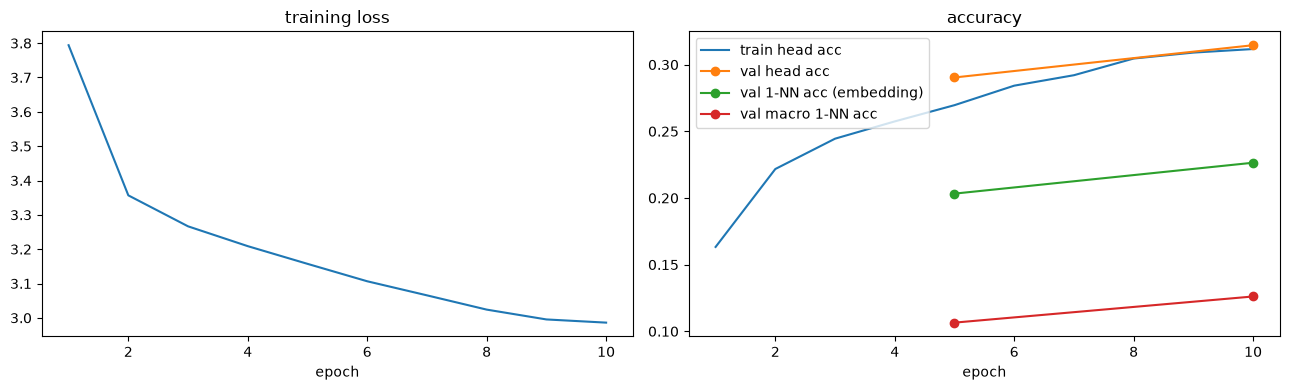

In [14]:
hist = pd.DataFrame(history)
ev = hist.dropna(subset=['val_knn1_acc'])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(hist['epoch'], hist['loss']); axes[0].set_title('training loss'); axes[0].set_xlabel('epoch')
axes[1].plot(hist['epoch'], hist['train_acc'], label='train head acc')
axes[1].plot(ev['epoch'], ev['val_head_acc'], marker='o', label='val head acc')
axes[1].plot(ev['epoch'], ev['val_knn1_acc'], marker='o', label='val 1-NN acc (embedding)')
axes[1].plot(ev['epoch'], ev['val_macro_acc1'], marker='o', label='val macro 1-NN acc')
axes[1].set_title('accuracy'); axes[1].set_xlabel('epoch'); axes[1].legend()
plt.tight_layout(); plt.savefig(RUN_DIR / 'minivit_curves.png', dpi=120); plt.show()

## 8. Test evaluation (best checkpoint)

In [15]:
ckpt = torch.load(best_path, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model'])
print('loaded epoch', ckpt['epoch'])

t0 = time.time()
_ = embed_crops(model.embedder, crops['test'])
sec_per_crop = (time.time() - t0) / len(crops['test'])

test_m, test_pc, test_pred = evaluate(model, 'test')
fe.save_result('minivit', 'test', test_m,
               extra=dict(dim=VIT['embed_dim'], params=n_params, epoch=ckpt['epoch'], sec_per_crop=sec_per_crop,
                          crop_size=VIT['image_size'], notebook='03b'))

table = pd.DataFrame({'untrained': untrained_test, 'trained': test_m})
print(table.loc[['knn1_acc', 'knn3_acc', 'knn5_acc', 'knn10_acc', 'top5_hit', 'macro_acc1', 'head_acc']]
      .to_string(float_format=lambda v: f'{v:.4f}'))

loaded epoch 10
            untrained  trained
knn1_acc       0.1479   0.2233
knn3_acc       0.1572   0.2400
knn5_acc       0.1747   0.2634
knn10_acc      0.2038   0.2943
top5_hit       0.3959   0.4937
macro_acc1     0.0693   0.1273
head_acc       0.0419   0.3272


In [16]:
pc = pd.DataFrame(test_pc).T
pc['name'] = [NAMES[c] for c in pc.index]
pc = pc[pc['n'] >= 10].sort_values('acc')
print('Hardest classes (n >= 10 test regions):'); print(pc.head(10)[['name', 'n', 'acc']].to_string())
print('\nEasiest classes:'); print(pc.tail(10)[['name', 'n', 'acc']].to_string())

Hardest classes (n >= 10 test regions):
                  name     n       acc
103  other ingredients  26.0  0.000000
81             pumpkin  17.0  0.000000
71              garlic  18.0  0.000000
61               pizza  10.0  0.000000
40           pineapple  23.0  0.000000
9        cheese butter  52.0  0.019231
3         french fries  31.0  0.032258
54                fish  58.0  0.034483
10                cake  77.0  0.038961
56              shrimp  25.0  0.040000

Easiest classes:
             name      n       acc
89  cilantro mint  128.0  0.281250
82       cucumber   80.0  0.300000
8       ice cream  135.0  0.311111
24            egg   23.0  0.391304
73         tomato  164.0  0.408537
30     strawberry   90.0  0.422222
31         cherry   34.0  0.529412
87       broccoli  140.0  0.550000
84         carrot  178.0  0.679775
32      blueberry   37.0  0.783784


## 9. Visualising attention

ViT attention maps are inspectable: the CLS token's attention over the patches shows what each head "looks at".
After training, heads should concentrate on the food rather than on the zeroed background.

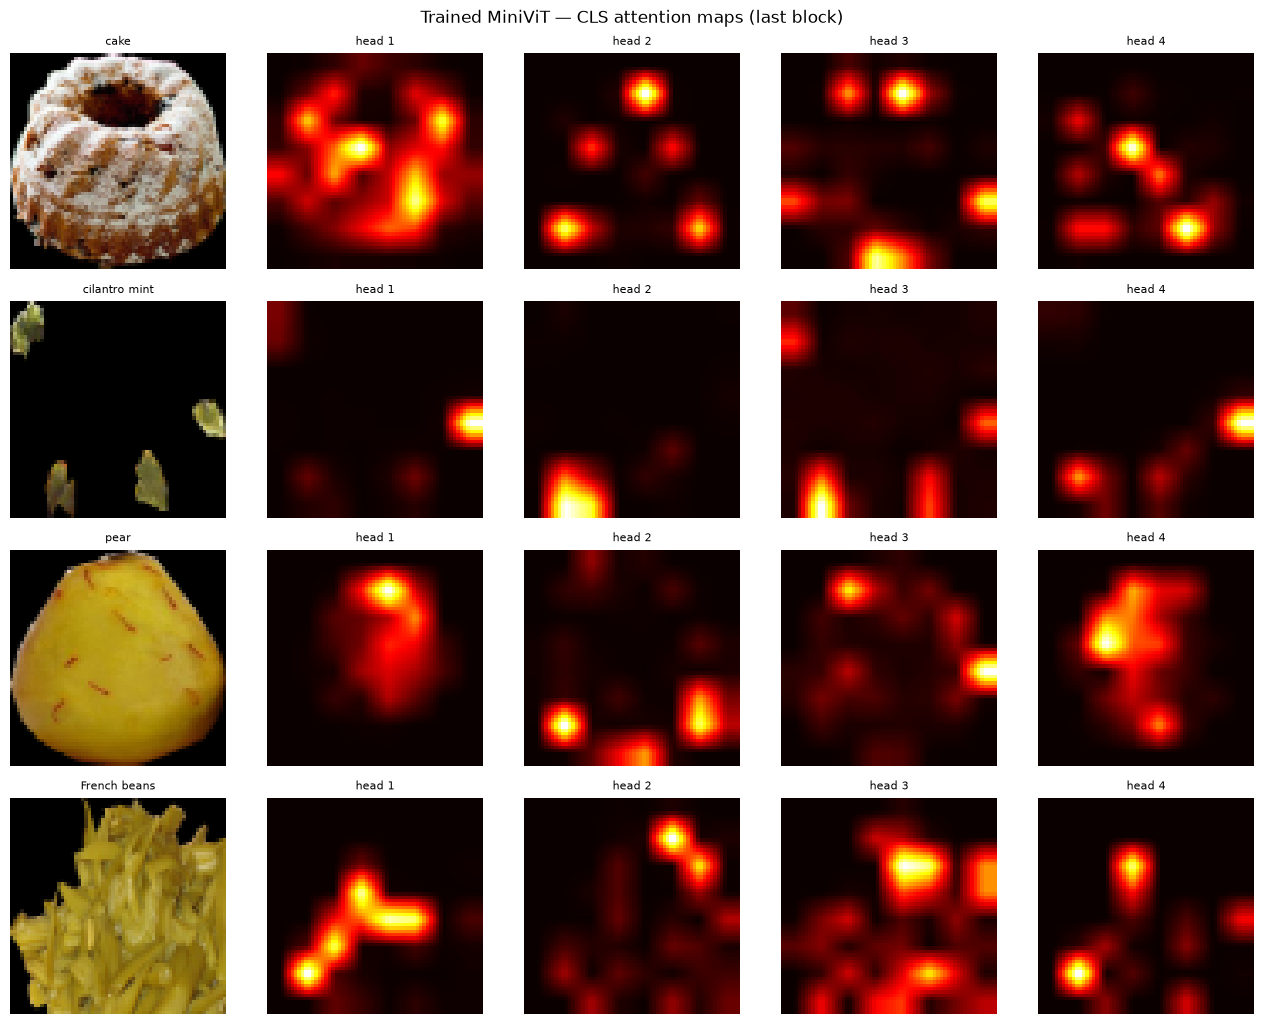

In [17]:
def cls_attention(embedder, x):
    """CLS→patch attention of the last block, shape (B, heads, side, side)."""
    store = {}
    def hook(module, inputs, output):
        B, N, D = inputs[0].shape
        qkv = module.qkv(inputs[0]).reshape(B, N, 3, module.num_heads, module.head_dim).permute(2, 0, 3, 1, 4)
        store['attn'] = torch.softmax((qkv[0] @ qkv[1].transpose(-2, -1)) * module.scale, dim=-1)
    handle = embedder.blocks[-1].attn.register_forward_hook(hook)
    with torch.no_grad():
        embedder(x)
    handle.remove()
    side = embedder.image_size // embedder.patch_size
    return store['attn'][:, :, 0, 1:].reshape(x.shape[0], -1, side, side).cpu().numpy()


idx = np.random.default_rng(1).choice(len(crops['test']), 4, replace=False)
att = cls_attention(model.embedder, to_input(crops['test'][idx]).to(device))
heads = att.shape[1]
fig, axes = plt.subplots(len(idx), heads + 1, figsize=(2.6 * (heads + 1), 2.6 * len(idx)))
for row, i, a_ in zip(axes, idx, att):
    row[0].imshow(crops['test'][i]); row[0].set_title(NAMES[labels['test'][i]], fontsize=8); row[0].axis('off')
    for h, ax in enumerate(row[1:]):
        ax.imshow(cv2.resize(a_[h], (VIT['image_size'],) * 2, interpolation=cv2.INTER_LINEAR), cmap='hot')
        ax.set_title(f'head {h + 1}', fontsize=8); ax.axis('off')
plt.suptitle('Trained MiniViT — CLS attention maps (last block)'); plt.tight_layout(); plt.show()

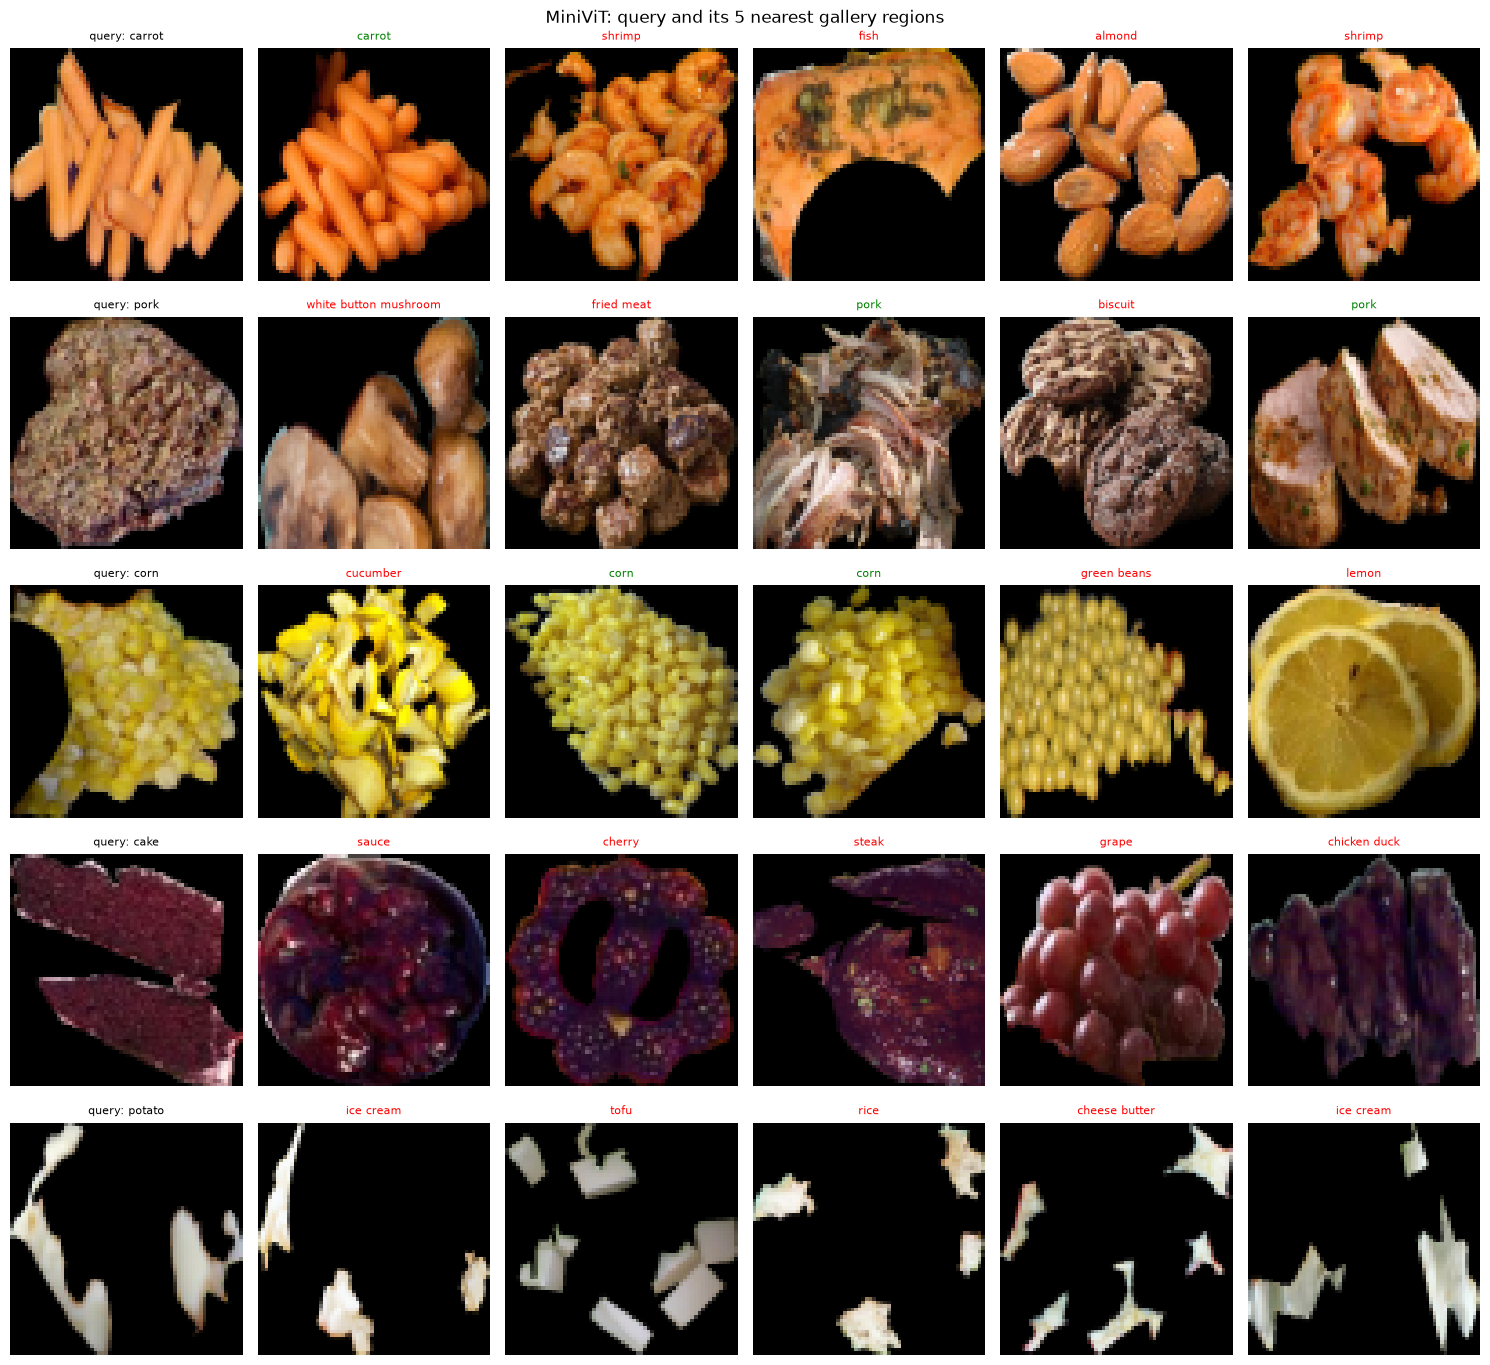

In [18]:
# Nearest-neighbour retrieval for a few test queries (green = same class as the query)
g = embed_crops(model.embedder, crops['train'])
q = embed_crops(model.embedder, crops['test'])
_, nn_idx = fe.knn_search(g, q, 5)
qs = np.random.default_rng(0).choice(len(q), size=5, replace=False)
fig, axes = plt.subplots(len(qs), 6, figsize=(15, 2.8 * len(qs)))
fe.show_retrievals(axes, crops['test'][qs], labels['test'][qs], lambda j: crops['train'][j], nn_idx[qs],
                   labels['train'], NAMES)
plt.suptitle('MiniViT: query and its 5 nearest gallery regions', fontsize=12)
plt.tight_layout(); plt.show()